# Abalone measurements and shell rings
## Endterm — Data Analysis and Visualization, Theory N4
**VibeCoding_Expert** · NGO LAM TIEN (524H0195) · NGUYEN CONG THANH (524H0191) · NGUYEN LE NHAT TAM (524H0186) · NGO BINH MINH (524H0169)  
Advisor: Ho Thi Linh, Ph.D. · Report date20October2026.

This notebook answers one coherent question: how do scaled physical measurements and M/F/I groups relate to shell rings, and how well does multiple linear regression predict Rings? It follows all six assignment sections. Public source: [UCI Abalone](https://doi.org/10.24432/C55C7W), Nash et al. (1994), CC BY4.0. The group did not collect these biological measurements. The user has confirmed dataset selection. The video link and actual contribution/completion records remain pending.

**Design fixed before inference:** stratified80/20 split, seed42; detailed EDA/inference and model development on train; untouched test for one final comparison of prespecified models. The preliminary source check established schema and obvious measurement issues. No predictive or causal performance is promised. I means infant, not a third biological sex. Measurements are retained as stored (the source states division by200); axes explicitly identify scaled values.

In [1]:
from pathlib import Path
import hashlib, json, sys, importlib.metadata
import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib','inline')
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, KFold
from sklearn.dummy import DummyRegressor
ROOT=Path.cwd().resolve()
if not (ROOT/"data/raw/abalone.data").exists() and not (ROOT/"abalone.data").exists(): ROOT=ROOT.parent
raw_candidate = ROOT/"abalone.data" if (ROOT/"abalone.data").exists() else (ROOT/"data/raw/abalone.data")
assert raw_candidate.exists(), f"Data file not found at {raw_candidate}"
sys.path.insert(0,str(ROOT))
try:
    from src.analysis import *
except ImportError:
    """Small shared statistical operations; every analysis uses the saved train split."""
    import numpy as np
    import pandas as pd
    from scipy import stats
    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LinearRegression
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from statsmodels.stats.multitest import multipletests
    import statsmodels.api as sm
    
    COLUMNS = ['sex','length','diameter','height','whole_weight','shucked_weight','viscera_weight','shell_weight','rings']
    NUMERIC = COLUMNS[1:]
    FULL = COLUMNS[:-1]
    COMPACT = ['sex','length','diameter','height','whole_weight']
    GROUPS = ['F','I','M']
    
    
    def clean_measurements(raw):
        if raw.columns.tolist() != COLUMNS or not raw['sex'].isin(GROUPS).all():
            raise ValueError('Unexpected schema or group code.')
        numeric=raw[NUMERIC].to_numpy(dtype=float)
        if not np.isfinite(numeric).all() or (raw['rings'] < 1).any() or (raw['rings'] % 1 != 0).any():
            raise ValueError('Invalid finite numerical values or rings.')
        if (raw[NUMERIC[:-1]] < 0).any().any():
            raise ValueError('Negative physical measurements require source review.')
        result=raw.copy()
        flagged=result['height'].eq(0)
        result.loc[flagged,'height']=np.nan
        return result, result.index[flagged].tolist()
    
    
    def ring_bands(rings):
        if rings.isna().any() or not ((rings>=1)&(rings%1==0)).all():
            raise ValueError('Rings must be positive finite integers.')
        return pd.cut(rings,bins=[0,8,10,np.inf],labels=['1–8','9–10','11+'])
    
    
    def holm(pvalues):
        p=np.asarray(pvalues,dtype=float)
        if p.ndim!=1 or len(p)==0 or not np.isfinite(p).all() or ((p<0)|(p>1)).any():
            raise ValueError('Expected a nonempty vector of valid p-values.')
        return multipletests(p,method='holm')[1]
    
    
    def welch_comparison(a,b):
        a,b=np.asarray(a,dtype=float),np.asarray(b,dtype=float)
        if min(len(a),len(b))<2 or not np.isfinite(a).all() or not np.isfinite(b).all():
            raise ValueError('Each finite group needs at least two observations.')
        test=stats.ttest_ind(a,b,equal_var=False)
        ci=test.confidence_interval(.95)
        return {'difference':float(a.mean()-b.mean()),'ci_low':float(ci.low),'ci_high':float(ci.high),
                'statistic':float(test.statistic),'df':float(test.df),'p':float(test.pvalue),'n_a':len(a),'n_b':len(b)}
    
    
    def contingency_test(table,seed=42,n_resamples=9999):
        observed=np.asarray(table,dtype=float)
        if observed.ndim!=2 or min(observed.shape)<2 or (observed<0).any() or (observed%1!=0).any():
            raise ValueError('Expected a nonnegative integer contingency table.')
        if (observed.sum(axis=0)==0).any() or (observed.sum(axis=1)==0).any():
            raise ValueError('Empty margins must be removed and documented.')
        chi,p,df,expected=stats.chi2_contingency(observed,correction=False)
        method='Pearson chi-square approximation'
        if (expected<5).any():
            simulated=stats.random_table.rvs(observed.sum(axis=1).astype(int),observed.sum(axis=0).astype(int),size=n_resamples,random_state=np.random.default_rng(seed))
            scores=((simulated-expected)**2/expected).sum(axis=(1,2))
            p=(1+np.count_nonzero(scores>=chi-1e-12))/(n_resamples+1)
            method=f'Fixed-margin Monte Carlo ({n_resamples} resamples)'
        v=np.sqrt(chi/(observed.sum()*min(observed.shape[0]-1,observed.shape[1]-1)))
        return {'statistic':float(chi),'p':float(p),'df':int(df),'min_expected':float(expected.min()),'cramers_v':float(v),'method':method},expected
    
    
    def regression_pipeline(features):
        numeric=[column for column in features if column!='sex']
        preprocess=ColumnTransformer([
            ('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),numeric),
            ('group',OneHotEncoder(categories=[GROUPS],drop='first',handle_unknown='error',sparse_output=False),['sex'])],verbose_feature_names_out=False)
        return Pipeline([('preprocess',preprocess),('regression',LinearRegression())])
    
    
    def metrics(y,prediction):
        y,prediction=np.asarray(y,dtype=float),np.asarray(prediction,dtype=float)
        if y.shape!=prediction.shape or y.ndim!=1 or len(y)<2 or not np.isfinite(y).all() or not np.isfinite(prediction).all():
            raise ValueError('Expected aligned finite response and prediction vectors.')
        return {'mae':float(mean_absolute_error(y,prediction)), 'rmse':float(np.sqrt(mean_squared_error(y,prediction))), 'r2':float(r2_score(y,prediction))}
    
    
    def cook_filter_fit(X,y,features):
        """Fit the influence screen only on the supplied training observations."""
        initial=regression_pipeline(features).fit(X,y)
        design=sm.add_constant(initial['preprocess'].transform(X),has_constant='add')
        fit=sm.OLS(np.asarray(y),design).fit()
        cooks=fit.get_influence().cooks_distance[0]
        keep=cooks<=4/len(X)
        if keep.sum()<=design.shape[1]:raise ValueError('Influence filtering left too few training rows.')
        final=regression_pipeline(features).fit(X.iloc[keep],y.iloc[keep])
        return final,keep,cooks
SEED=42
T=ROOT/'results/tables';F=ROOT/'results/figures'
T.mkdir(parents=True,exist_ok=True);F.mkdir(parents=True,exist_ok=True)
(ROOT/"data/processed").mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_columns',None)
sns.set_theme(style='whitegrid',font='DejaVu Sans',font_scale=1.05)
COLORS={'F':'#CC6677','I':'#228833','M':'#4477AA'}
plt.rcParams.update({'figure.dpi':100,'savefig.dpi':180,'axes.titleweight':'bold','svg.hashsalt':'tdtu-nor'})
def save_table(frame,name,index=False):frame.to_csv(T/f'{name}.csv',index=index)
def save_figure(fig,name):
    fig.tight_layout();fig.savefig(F/f'{name}.png',bbox_inches='tight',facecolor='white')
    fig.savefig(F/f'{name}.svg',bbox_inches='tight',facecolor='white',metadata={'Date':None})
    plt.show()
def dump(path,value):path.write_text(json.dumps(value,indent=2,allow_nan=False,default=lambda x:x.item() if isinstance(x,np.generic) else x.tolist())+'\n')

## 1. Exploratory data analysis
### 1.1 Source and structural validation
The CSV has no header. UCI supplies8features plus Rings, the target:9columns total. The source had already removed examples with missing values, so the absence of missing cells is not proof that the original field study was complete. The current source has no site or batch identifiers, which limits independence assumptions and validation across locations.

In [2]:
source_p = ROOT/"references/dataset_source.json"
expected_sha = json.loads(source_p.read_text())["raw_sha256"] if source_p.exists() else "de37cdcdcaaa50c309d514f248f7c2302a5f1f88c168905eba23fe2fbc78449f"
raw_path = ROOT/"abalone.data" if (ROOT/"abalone.data").exists() else (ROOT/"data/raw/abalone.data")
raw_hash=hashlib.sha256(raw_path.read_bytes()).hexdigest()
assert raw_hash == expected_sha
raw=pd.read_csv(raw_path,header=None,names=COLUMNS)
raw.index.name='source_index'
assert raw.shape==(4177,9) and raw.isna().sum().sum()==0 and raw.duplicated().sum()==0
print('Original shape:',raw.shape,'SHA256:',raw_hash)
display(raw.head());display(raw.tail());raw.info()
display(raw.dtypes.astype(str).rename('dtype').to_frame())

Original shape: (4177, 9) SHA256: de37cdcdcaaa50c309d514f248f7c2302a5f1f88c168905eba23fe2fbc78449f


,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
source_index,,,,,,,,,
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
source_index,,,,,,,,,
4172,F,0.565,0.450,0.165,0.8870,0.3700,0.2390,0.2490,11
4173,M,0.590,0.440,0.135,0.9660,0.4390,0.2145,0.2605,10
4174,M,0.600,0.475,0.205,1.1760,0.5255,0.2875,0.3080,9
4175,F,0.625,0.485,0.150,1.0945,0.5310,0.2610,0.2960,10
4176,M,0.710,0.555,0.195,1.9485,0.9455,0.3765,0.4950,12


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sex             4177 non-null   object 
 1   length          4177 non-null   float64
 2   diameter        4177 non-null   float64
 3   height          4177 non-null   float64
 4   whole_weight    4177 non-null   float64
 5   shucked_weight  4177 non-null   float64
 6   viscera_weight  4177 non-null   float64
 7   shell_weight    4177 non-null   float64
 8   rings           4177 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 293.8+ KB


,dtype
sex,object
length,float64
diameter,float64
height,float64
whole_weight,float64
shucked_weight,float64
viscera_weight,float64
shell_weight,float64
rings,int64


### 1.2 Quality rules and saved holdout
Height=0 cannot represent a positive shell thickness: flag and replace only these two cells with NaN. Other extremes are not silently edited. The cleaning rule is domain-based and fixed before splitting. The source observations remain unchanged. Univariate descriptions omit the invalid heights, reporting their n; model median imputation is fit only within training folds.

In [3]:
clean,invalid_height=clean_measurements(raw)
assert len(invalid_height)==2
train_idx,test_idx=train_test_split(clean.index.to_numpy(),test_size=.2,random_state=SEED,stratify=clean.sex)
assert len(set(train_idx)&set(test_idx))==0 and set(train_idx)|set(test_idx)==set(raw.index)
train=clean.loc[train_idx].copy();test=clean.loc[test_idx].copy()
split=pd.DataFrame({'source_index':raw.index,'split':np.where(raw.index.isin(train_idx),'train','test')})
split.to_csv(ROOT/'data/processed/split.csv',index=False)
clean.to_csv(ROOT/'data/processed/clean_measurements.csv')
audit=pd.DataFrame({'source_index':invalid_height,'column':'height','raw_value':0,'action':'set to NaN; training-only median imputation in regression'})
save_table(audit,'quality_audit')
display(audit);print('Train:',len(train),'Test:',len(test))
display(pd.crosstab(split['split'],raw.sex.to_numpy()))

,source_index,column,raw_value,action
0,1257,height,0,set to NaN; training-only median imputation in...
1,3996,height,0,set to NaN; training-only median imputation in...


Train: 3341 Test: 836


col_0,F,I,M
split,,,
test,261,269,306
train,1046,1073,1222


All following detailed descriptions and tests use train only: n = 3341


,count,mean,std,min,25%,50%,75%,max
length,3341.0,0.524054,0.119819,0.1300,0.4500,0.5450,0.6150,0.8150
diameter,3341.0,0.407984,0.098967,0.0950,0.3500,0.4250,0.4800,0.6500
height,3339.0,0.139678,0.041933,0.0150,0.1150,0.1400,0.1650,1.1300
whole_weight,3341.0,0.828287,0.488599,0.0105,0.4440,0.8000,1.1545,2.8255
shucked_weight,3341.0,0.358867,0.220658,0.0045,0.1870,0.3345,0.5010,1.4880
viscera_weight,3341.0,0.180234,0.108787,0.0005,0.0935,0.1700,0.2530,0.7600
shell_weight,3341.0,0.238981,0.138833,0.0035,0.1300,0.2350,0.3300,1.0050
rings,3341.0,9.936247,3.212784,2.0000,8.0000,9.0000,11.0000,27.0000


length                                          rings             \
     count      mean       std median    min    max count       mean   
sex                                                                    
F     1046  0.578685  0.085379  0.590  0.290  0.815  1046  11.092734   
I     1073  0.426775  0.107969  0.435  0.130  0.680  1073   7.895620   
M     1222  0.562709  0.102129  0.580  0.155  0.780  1222  10.738134   

                              
          std median min max  
sex                           
F    3.027467   10.0   5  27  
I    2.516051    8.0   2  21  
M    3.063377   10.0   3  27

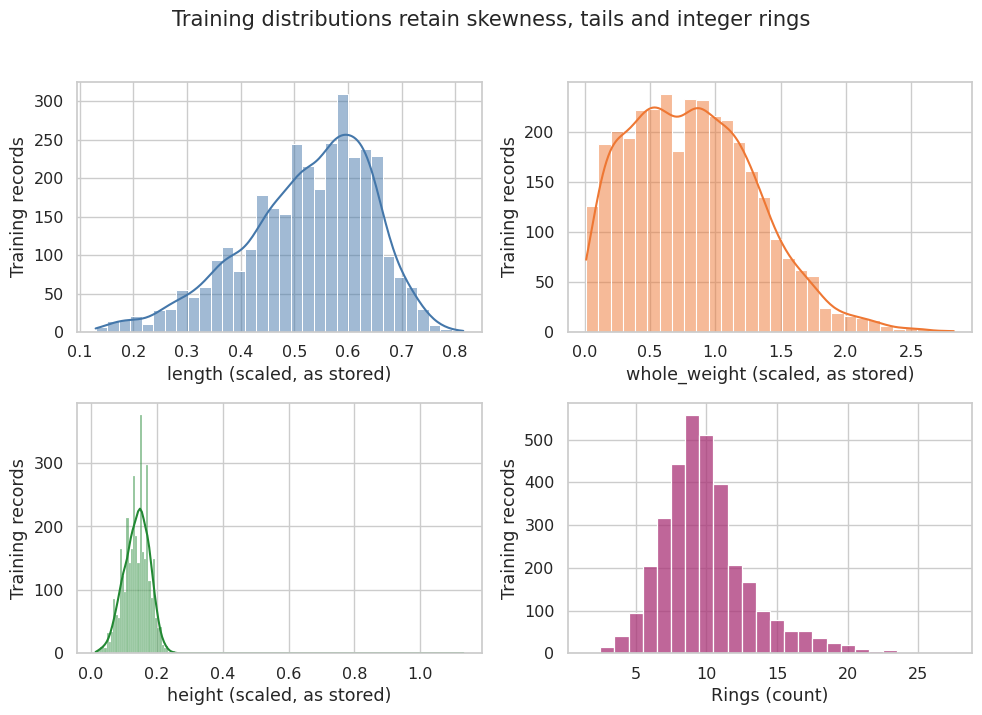

In [4]:
descriptive=train[NUMERIC].describe().T
save_table(descriptive,'descriptive_train',index=True)
group_stats=train.groupby('sex',observed=True)[['length','rings']].agg(['count','mean','std','median','min','max'])
save_table(group_stats,'group_statistics',index=True)
print('All following detailed descriptions and tests use train only: n =',len(train))
display(descriptive);display(group_stats)
fig,axes=plt.subplots(2,2,figsize=(10,7))
for ax,col,color in zip(axes.flat,['length','whole_weight','height','rings'],['#4477AA','#EE7733','#228833','#AA3377']):
    sns.histplot(data=train,x=col,kde=col!='rings',discrete=col=='rings',color=color,ax=ax)
    ax.set_xlabel('Rings (count)' if col=='rings' else f'{col} (scaled, as stored)');ax.set_ylabel('Training records')
fig.suptitle('Training distributions retain skewness, tails and integer rings',y=1.02)
save_figure(fig,'01_eda_distributions')

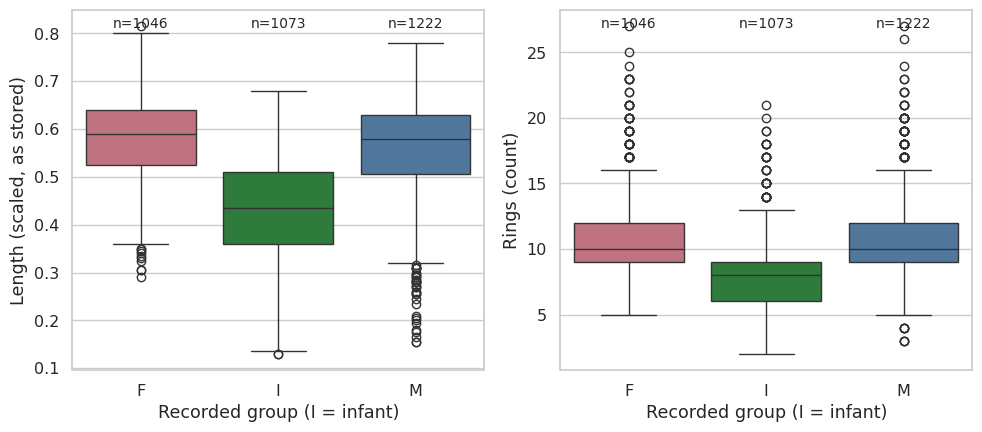

,flagged_count,percent
length,44,1.316971
diameter,51,1.526489
height,22,0.658485
whole_weight,25,0.748279
shucked_weight,38,1.137384
viscera_weight,21,0.628554
shell_weight,24,0.718348
rings,225,6.734511


IQR flags identify unusual records, not confirmed measurement errors. No IQR-based deletion.


In [5]:
fig,axes=plt.subplots(1,2,figsize=(10,4.5))
for ax,col in zip(axes,['length','rings']):
    sns.boxplot(data=train,x='sex',y=col,hue='sex',order=GROUPS,hue_order=GROUPS,palette=COLORS,legend=False,ax=ax)
    ax.set_xlabel('Recorded group (I = infant)');ax.set_ylabel('Rings (count)' if col=='rings' else 'Length (scaled, as stored)')
    for i,g in enumerate(GROUPS):ax.text(i,.98,f'n={sum(train.sex==g)}',transform=ax.get_xaxis_transform(),ha='center',va='top',fontsize=10)
save_figure(fig,'02_group_boxplots')
q1=train[NUMERIC].quantile(.25);q3=train[NUMERIC].quantile(.75);iqr=q3-q1
flags=(train[NUMERIC].lt(q1-1.5*iqr)|train[NUMERIC].gt(q3+1.5*iqr))
outlier_counts=flags.sum().rename('flagged_count').to_frame();outlier_counts['percent']=outlier_counts.flagged_count/len(train)*100
save_table(outlier_counts,'iqr_counts',True)
flagged=train.loc[flags.any(axis=1)].copy();flagged['flagged_columns']=flags.loc[flags.any(axis=1)].apply(lambda row:', '.join(row.index[row]),axis=1)
save_table(flagged,'iqr_flagged_training_rows',True)
display(outlier_counts);print('IQR flags identify unusual records, not confirmed measurement errors. No IQR-based deletion.')

## 2. Probability distributions
A normal distribution has density proportional to exp(−(x−μ)²/(2σ²)); a positive variable is lognormal when its logarithm is normal. These are candidate families, not assertions. We compare Length with Normal and Whole_weight with Normal and Lognormal. AD statistics emphasize tail discrepancies.

`goodness_of_fit` refits unknown μ and σ for every Monte Carlo sample. A plain KS p-value after fitting parameters to the same observations is not used. For a lognormal family with location0, the normality check is performed on log(weight). There are1999resamples per test and three Holm-adjusted distribution tests. P-values cannot be below1/2000; rounded observations and large sample size limit an exact continuous-distribution interpretation.

In [6]:
distribution_rows=[]
for offset,(label,column,logged) in enumerate([('Length / Normal','length',False),('Weight / Normal','whole_weight',False),('Weight / Lognormal','whole_weight',True)]):
    values=train[column].dropna().to_numpy()
    if logged:values=np.log(values)
    result=stats.goodness_of_fit(stats.norm,values,statistic='ad',n_mc_samples=1999,rng=np.random.default_rng(SEED+offset))
    distribution_rows.append({'hypothesis':label,'n':len(values),'ad':float(result.statistic),'p':float(result.pvalue),
                              'mu':float(values.mean()),'sigma':float(values.std(ddof=1)),'seed':SEED+offset})
distribution=pd.DataFrame(distribution_rows);distribution['p_holm']=holm(distribution.p)
distribution['reject_05']=distribution.p_holm<.05
save_table(distribution,'distribution_tests');display(distribution)

,hypothesis,n,ad,p,mu,sigma,seed,p_holm,reject_05
0,Length / Normal,3341,29.398852,0.0005,0.524054,0.119819,42,0.0015,True
1,Weight / Normal,3341,16.473064,0.0005,0.828287,0.488599,43,0.0015,True
2,Weight / Lognormal,3341,86.506415,0.0005,-0.439391,0.832877,44,0.0015,True


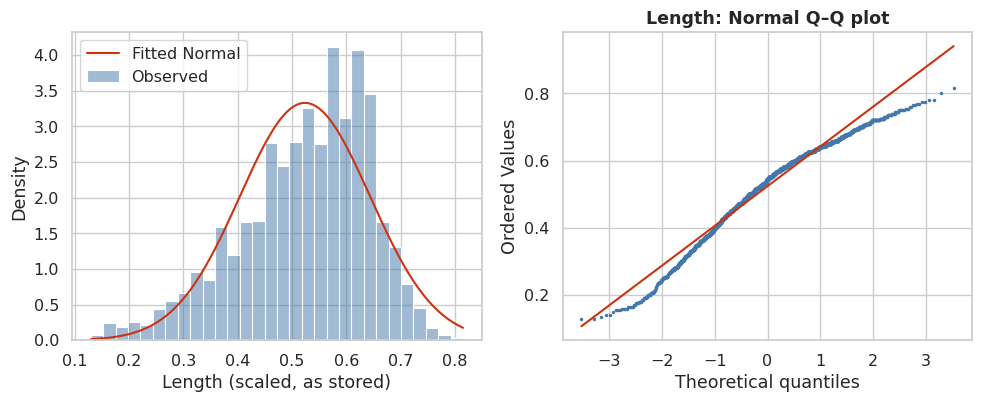

In [7]:
fig,axes=plt.subplots(1,2,figsize=(10,4.2))
x=train.length.to_numpy();grid=np.linspace(x.min(),x.max(),150);mu=x.mean();sd=x.std(ddof=1)
sns.histplot(x=x,stat='density',bins=30,color='#4477AA',alpha=.5,ax=axes[0],label='Observed')
axes[0].plot(grid,stats.norm.pdf(grid,mu,sd),color='#CC3311',label='Fitted Normal');axes[0].legend()
axes[0].set(xlabel='Length (scaled, as stored)',ylabel='Density')
stats.probplot(x,dist='norm',plot=axes[1]);axes[1].get_lines()[0].set(color='#4477AA',marker='.',markersize=3);axes[1].get_lines()[1].set_color('#CC3311')
axes[1].set_title('Length: Normal Q–Q plot')
save_figure(fig,'03_length_distribution')

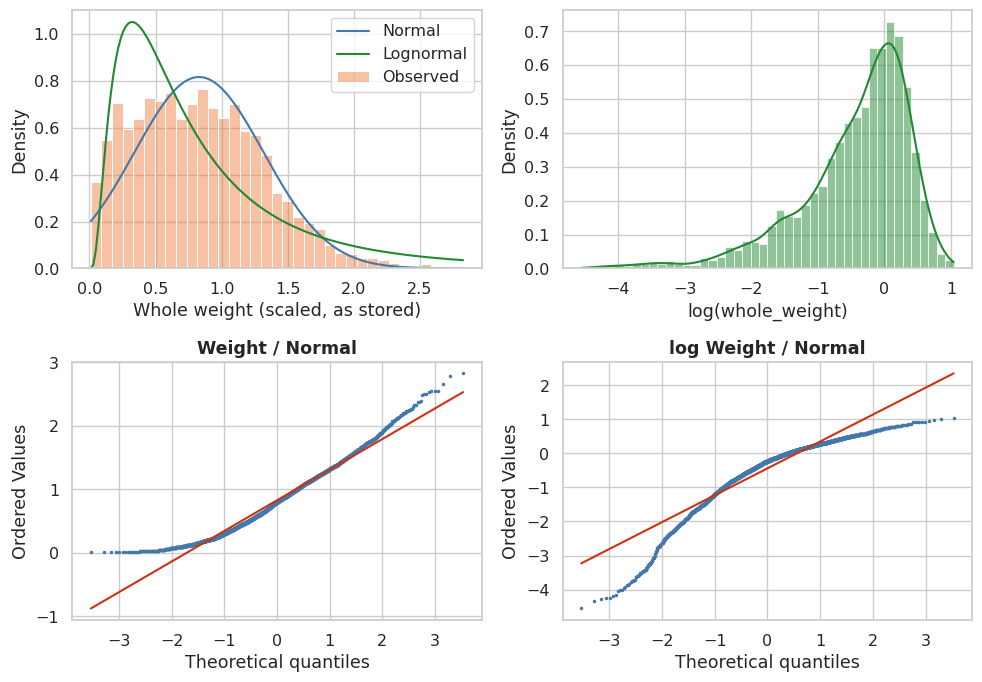

In [8]:
fig,axes=plt.subplots(2,2,figsize=(10,7))
w=train.whole_weight.to_numpy();grid_w=np.linspace(w.min(),w.max(),150)
mu_w=w.mean();sd_w=w.std(ddof=1);logmu=np.log(w).mean();logsd=np.log(w).std(ddof=1)
sns.histplot(x=w,stat='density',bins=35,color='#EE7733',alpha=.45,ax=axes[0,0],label='Observed')
axes[0,0].plot(grid_w,stats.norm.pdf(grid_w,mu_w,sd_w),color='#4477AA',label='Normal')
axes[0,0].plot(grid_w,stats.lognorm.pdf(grid_w,logsd,scale=np.exp(logmu)),color='#228833',label='Lognormal')
axes[0,0].legend();axes[0,0].set(xlabel='Whole weight (scaled, as stored)',ylabel='Density')
sns.histplot(x=np.log(w),stat='density',kde=True,color='#228833',ax=axes[0,1]);axes[0,1].set_xlabel('log(whole_weight)')
for ax,values,title in [(axes[1,0],w,'Weight / Normal'),(axes[1,1],np.log(w),'log Weight / Normal')]:
    stats.probplot(values,dist='norm',plot=ax);ax.get_lines()[0].set(color='#4477AA',marker='.',markersize=3);ax.get_lines()[1].set_color('#CC3311');ax.set_title(title)
save_figure(fig,'04_weight_distribution')

## 3. Hypothesis testing
**Welch t-test:** H0: mean Rings(M)=mean Rings(F), two-sided. It compares independent means allowing unequal variances, with Satterthwaite degrees of freedom. Report the mean difference M−F and its95%CI.

**Chi-square independence:** H0: recorded group and ring band are independent. Bands1–8/9–10/11+ follow a historical coding described in the retained codebook; they are not validated biological age classes. Use Pearson χ² with df=(r−1)(c−1), check expected counts; sparse tables use fixed-margin Monte Carlo.

**One-way ANOVA:** classical ANOVA compares between-group and within-group variability under common variance. Welch ANOVA instead weights unequal group variances and adjusts degrees of freedom. Primary H0: mean Length(F)=mean Length(I)=mean Length(M). Independence remains an assumption, because site/batch IDs are absent. Welch methods tolerate unequal variances but do not remove confounding, selection bias or clustered sampling.

Alpha=.05; Holm correction applies to the three primary tests as one family. Follow-up pairwise Length comparisons form a separate Holm family only if the omnibus adjusted result rejects. Failure to reject is not proof of equality, and statistical significance does not measure practical importance.

In [9]:
welch=welch_comparison(train.loc[train.sex=='M','rings'],train.loc[train.sex=='F','rings'])
contingency=pd.crosstab(train.sex,ring_bands(train.rings)).reindex(GROUPS)
chi,expected=contingency_test(contingency)
length_groups=[train.loc[train.sex==g,'length'].to_numpy() for g in GROUPS]
anova=anova_oneway(length_groups,use_var='unequal',welch_correction=True)
classic=stats.f_oneway(*length_groups)
levene=stats.levene(*length_groups,center='median')
overall_mean=train.length.mean()
ss_between=sum(len(a)*(a.mean()-overall_mean)**2 for a in length_groups)
eta_sq=float(ss_between/np.sum((train.length-overall_mean)**2))
hypotheses=pd.DataFrame([
 {'test':'Welch t: Rings M−F','statistic':welch['statistic'],'df1':welch['df'],'df2':np.nan,'p':welch['p']},
 {'test':'Chi-square: group × ring band','statistic':chi['statistic'],'df1':chi['df'],'df2':np.nan,'p':chi['p']},
 {'test':'Welch ANOVA: Length groups','statistic':float(anova.statistic),'df1':float(anova.df_num),'df2':float(anova.df_denom),'p':float(anova.pvalue)}])
hypotheses['p_holm']=holm(hypotheses.p);hypotheses['reject_05']=hypotheses.p_holm<.05
save_table(hypotheses,'hypothesis_tests');save_table(contingency,'contingency_observed',True)
save_table(pd.DataFrame(expected,index=GROUPS,columns=contingency.columns),'contingency_expected',True)
display(hypotheses);print('Welch difference and CI:',welch);print('Chi-square diagnostics:',chi)
print('Classical ANOVA reference:',classic,'Median-based Levene:',levene,'Descriptive eta-squared:',eta_sq)

,test,statistic,df1,df2,p,p_holm,reject_05
0,Welch t: Rings M−F,-2.765429,2219.982161,NaN,5.731834e-03,5.731834e-03,True
1,Chi-square: group × ring band,925.827048,4.000000,NaN,4.223260e-199,8.446521e-199,True
2,Welch ANOVA: Length groups,720.440722,2.000000,2201.275757,2.031639e-241,6.094917e-241,True


Welch difference and CI: {'difference': -0.3546000194021026, 'ci_low': -0.6060555731404269, 'ci_high': -0.10314446566377827, 'statistic': -2.765428661571336, 'df': 2219.9821609494506, 'p': 0.005731833545976567, 'n_a': 1222, 'n_b': 1046}
Chi-square diagnostics: {'statistic': 925.8270484477547, 'p': 4.223260443126345e-199, 'df': 4, 'min_expected': 334.6824304100569, 'cramers_v': 0.3722302780449333, 'method': 'Pearson chi-square approximation'}
Classical ANOVA reference: F_onewayResult(statistic=np.float64(767.2778039909691), pvalue=np.float64(6.801151883244679e-275)) Median-based Levene: LeveneResult(statistic=np.float64(25.664659341814634), pvalue=np.float64(8.685787718273731e-12)) Descriptive eta-squared: 0.3149385520543095


,comparison,difference,ci_low,ci_high,statistic,df,p,n_a,n_b,p_holm
0,F−I,0.151910,0.143628,0.160192,35.972661,2031.065925,1.113907e-219,1046,1073,3.341722e-219
1,F−M,0.015977,0.008255,0.023698,4.057537,2264.755732,5.127355e-05,1046,1222,5.127355e-05
2,I−M,-0.135933,-0.144571,-0.127296,-30.862310,2216.790573,2.678771e-174,1073,1222,5.357543e-174


Pairwise CIs are unadjusted95% descriptive intervals; only p-values have Holm familywise adjustment.


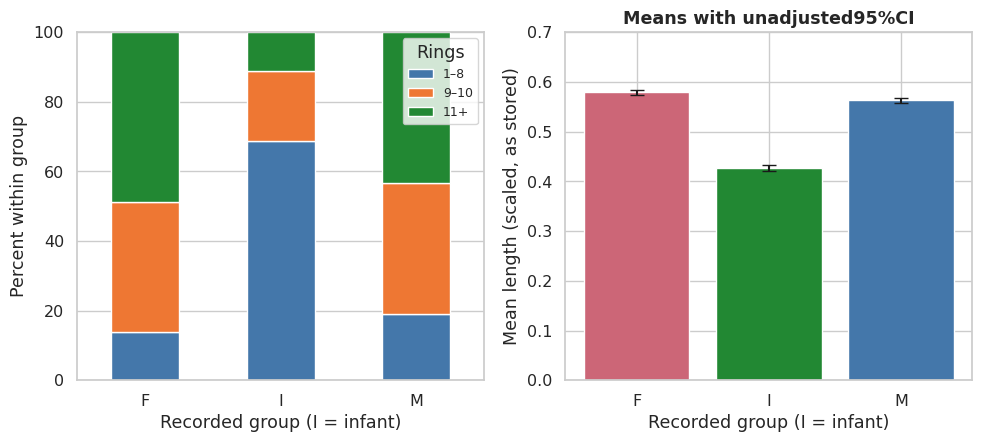

In [10]:
posthoc=[]
if hypotheses.loc[2,'reject_05']:
    for a,b in [('F','I'),('F','M'),('I','M')]:posthoc.append({'comparison':a+'−'+b,**welch_comparison(train.loc[train.sex==a,'length'],train.loc[train.sex==b,'length'])})
    pairwise=pd.DataFrame(posthoc);pairwise['p_holm']=holm(pairwise.p);save_table(pairwise,'anova_posthoc');display(pairwise)
print('Pairwise CIs are unadjusted95% descriptive intervals; only p-values have Holm familywise adjustment.')
fig,axes=plt.subplots(1,2,figsize=(10,4.6))
percent=contingency.div(contingency.sum(axis=1),axis=0)*100
percent.plot.bar(stacked=True,color=['#4477AA','#EE7733','#228833'],ax=axes[0],rot=0)
axes[0].set(xlabel='Recorded group (I = infant)',ylabel='Percent within group',ylim=(0,100));axes[0].legend(title='Rings',fontsize=9)
length_summary=train.groupby('sex').length.agg(['count','mean','std']).reindex(GROUPS)
length_summary['ci95']=stats.t.ppf(.975,length_summary['count']-1)*length_summary['std']/np.sqrt(length_summary['count'])
axes[1].bar(GROUPS,length_summary['mean'],yerr=length_summary.ci95,color=[COLORS[g] for g in GROUPS],capsize=5)
axes[1].set(xlabel='Recorded group (I = infant)',ylabel='Mean length (scaled, as stored)',ylim=(0,.7))
axes[1].set_title('Means with unadjusted95%CI')
save_figure(fig,'05_hypothesis_groups')

## 4. Pearson and Spearman correlation
Pearson r measures linear association using centered products. Spearman ρ applies Pearson correlation to ranks, using average ranks for ties. Their values are not causal effects and cannot by themselves measure independent predictor importance. Group is nominal and is not assigned an arbitrary numeric order. Pairwise n is exported because invalid heights are omitted from relevant pairs. Matrices exclude source indexes and outcome-derived variables.

,pearson,spearman,n,abs_spearman
shell_weight,0.627772,0.692772,3341,0.692772
height,0.548166,0.652742,3339,0.652742
whole_weight,0.540799,0.632187,3341,0.632187
diameter,0.575429,0.625291,3341,0.625291
viscera_weight,0.505112,0.615760,3341,0.615760
length,0.557119,0.605322,3341,0.605322
shucked_weight,0.420716,0.540536,3341,0.540536


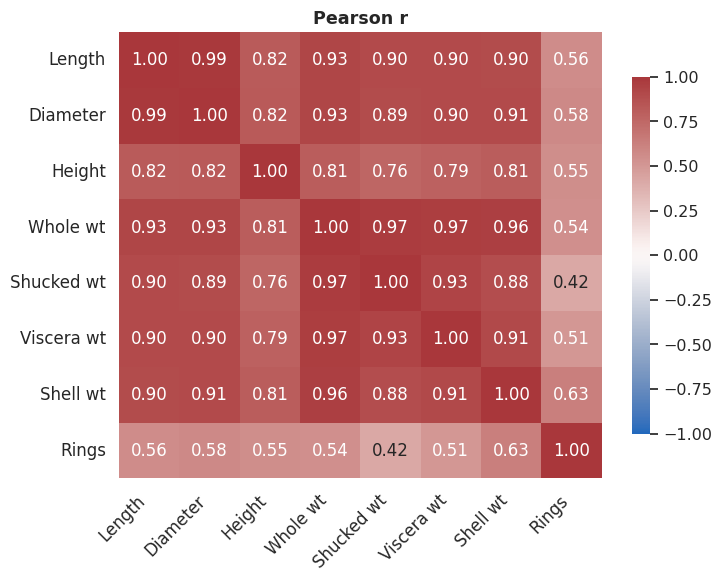

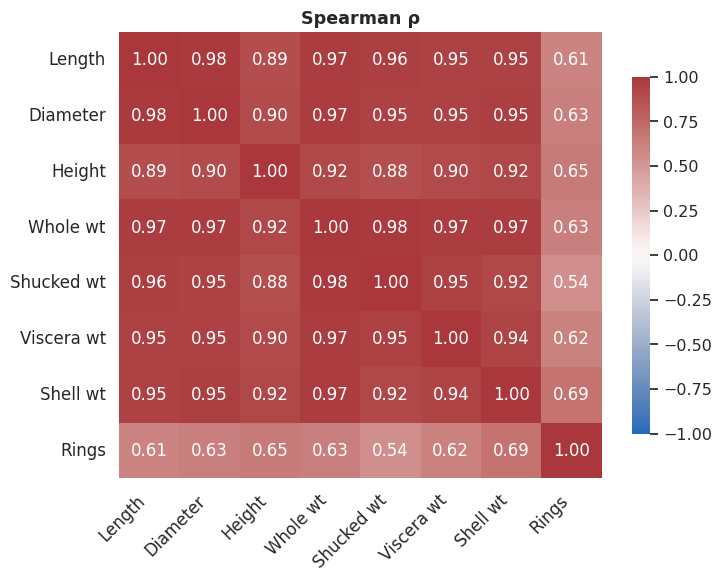

In [11]:
pearson=train[NUMERIC].corr(method='pearson');spearman=train[NUMERIC].corr(method='spearman')
pair_n=train[NUMERIC].notna().astype(int).T.dot(train[NUMERIC].notna().astype(int))
save_table(pearson,'pearson_matrix',True);save_table(spearman,'spearman_matrix',True);save_table(pair_n,'correlation_n',True)
correlations=pd.DataFrame({'pearson':pearson['rings'].drop('rings'),'spearman':spearman['rings'].drop('rings'),'n':pair_n['rings'].drop('rings')})
correlations['abs_spearman']=correlations.spearman.abs();correlations=correlations.sort_values('abs_spearman',ascending=False)
save_table(correlations,'rings_correlations',True);display(correlations)
labels=['Length','Diameter','Height','Whole wt','Shucked wt','Viscera wt','Shell wt','Rings']
for matrix,title,name in [(pearson,'Pearson r','06a_pearson_heatmap'),(spearman,'Spearman ρ','06b_spearman_heatmap')]:
    fig,ax=plt.subplots(figsize=(7.5,6))
    sns.heatmap(matrix,annot=True,fmt='.2f',cmap='vlag',vmin=-1,vmax=1,center=0,ax=ax,cbar=True,annot_kws={'fontsize':12},xticklabels=labels,yticklabels=labels,cbar_kws={'shrink':.8})
    ax.set_xticklabels(labels,rotation=45,ha='right',fontsize=12);ax.set_yticklabels(labels,rotation=0,fontsize=12);ax.set_title(title)
    save_figure(fig,name)

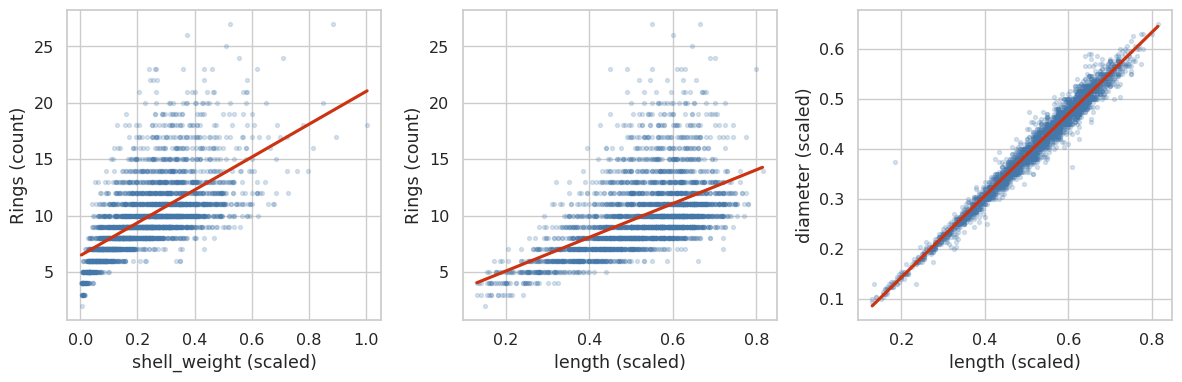

In [12]:
fig,axes=plt.subplots(1,3,figsize=(12,4))
for ax,a,b in [(axes[0],'shell_weight','rings'),(axes[1],'length','rings'),(axes[2],'length','diameter')]:
    sns.regplot(data=train,x=a,y=b,ci=None,scatter_kws={'alpha':.2,'s':8,'color':'#4477AA'},line_kws={'color':'#CC3311'},ax=ax)
    ax.set_xlabel(a+' (scaled)');ax.set_ylabel('Rings (count)' if b=='rings' else b+' (scaled)')
save_figure(fig,'07_relationships')

## 5. Multiple linear regression
OLS fits Rings=β0+ΣβjXj+ε by minimizing squared residuals. Multiple predictors allow conditional associations, but coefficients do not identify causal effects. A dummy for I and one for M use F as reference. Numeric coefficients below correspond to one training SD after median imputation; original-scale coefficients are exported separately.

Three prespecified methods: training-mean baseline; compact measurements (group, length, diameter, height, whole weight); full8original inputs. Component weights may require dissection: do not describe the full model as wholly nondestructive. An80/20holdout estimates performance on similarly sampled records, not new locations or cohorts. FivefoldCV on train estimates development variability. Every fold fits its own median and scaling; the test is not used to select or tune models.

In [13]:
folds=list(KFold(n_splits=5,shuffle=True,random_state=SEED).split(train))
models={'Baseline':None,'Compact':COMPACT,'Full':FULL}
cv_rows=[]
for name,features in models.items():
    for fold,(inner,valid) in enumerate(folds,1):
        a,b=train.iloc[inner],train.iloc[valid]
        if features is None:
            fitted=DummyRegressor(strategy='mean').fit(a[['length']],a.rings);prediction=fitted.predict(b[['length']])
        else:
            fitted=regression_pipeline(features).fit(a[features],a.rings);prediction=fitted.predict(b[features])
        cv_rows.append({'model':name,'fold':fold,**metrics(b.rings,prediction),'fit_n':len(a),'validation_n':len(b)})
cv=pd.DataFrame(cv_rows);save_table(cv,'cv_fold_metrics')
cv_summary=cv.groupby('model')[['mae','rmse','r2']].agg(['mean','std'])
save_table(cv_summary,'cv_summary',True);display(cv_summary)

mae                rmse                  r2          
              mean       std      mean       std      mean       std
model                                                               
Baseline  2.352576  0.142103  3.208097  0.203055 -0.001620  0.001090
Compact   1.830538  0.110254  2.622150  0.338752  0.332595  0.089743
Full      1.582987  0.084015  2.209580  0.149925  0.524886  0.014538

In [14]:
# One final holdout evaluation of all prespecified methods; no tuning follows.
fitted_models={};test_rows=[]
predictions=test[['sex','rings']].copy()
for name,features in models.items():
    model=DummyRegressor(strategy='mean').fit(train[['length']],train.rings) if features is None else regression_pipeline(features).fit(train[features],train.rings)
    prediction=model.predict(test[['length']] if features is None else test[features])
    fitted_models[name]=model;predictions[name]=prediction
    test_rows.append({'model':name,**metrics(test.rings,prediction),'outside_1_29':int(((prediction<1)|(prediction>29)).sum())})
test_metrics=pd.DataFrame(test_rows);save_table(test_metrics,'test_metrics');save_table(predictions,'test_predictions',True)
display(test_metrics)
full=fitted_models['Full'];Z=full['preprocess'].transform(train[FULL]);design=sm.add_constant(Z,has_constant='add')
assert np.linalg.matrix_rank(design)==design.shape[1]
ols=sm.OLS(train.rings.to_numpy(),design).fit();robust=ols.get_robustcov_results(cov_type='HC3')
np.testing.assert_allclose(ols.predict(design),full.predict(train[FULL]),atol=1e-10,rtol=0)
feature_names=['Intercept',*full['preprocess'].get_feature_names_out()]
interval=robust.conf_int()
coefficients=pd.DataFrame({'term':feature_names,'coefficient':robust.params,'HC3_SE':robust.bse,'ci_low':interval[:,0],'ci_high':interval[:,1]})
save_table(coefficients,'full_coefficients_HC3');display(coefficients)
# Convert numeric slopes and intercept back to stored-measurement units.
original=full['regression'].coef_.copy();scaler=full['preprocess'].named_transformers_['numeric']['scale'];original[:7]/=scaler.scale_
original_intercept=full['regression'].intercept_-np.dot(original[:7],scaler.mean_)
original_coefficients=pd.DataFrame({'term':feature_names,'coefficient':[original_intercept,*original]})
save_table(original_coefficients,'full_coefficients_stored_scale')
np.testing.assert_allclose(np.column_stack([np.ones(len(train)),full['preprocess'].named_transformers_['numeric']['impute'].transform(train[NUMERIC[:-1]]),Z[:,7:]])@original_coefficients.coefficient,full.predict(train[FULL]),atol=1e-10,rtol=0)

,model,mae,rmse,r2,outside_1_29
0,Baseline,2.403391,3.269263,-0.000015,0
1,Compact,1.851130,2.575851,0.379205,0
2,Full,1.599551,2.250944,0.525937,1


,term,coefficient,HC3_SE,ci_low,ci_high
0,Intercept,10.160228,0.079086,10.005166,10.315291
1,length,-0.097192,0.269908,-0.626395,0.432010
2,diameter,1.206769,0.328264,0.563150,1.850388
3,height,0.368789,0.505525,-0.622382,1.359960
4,whole_weight,4.589800,0.653369,3.308755,5.870846
5,shucked_weight,-4.557017,0.348714,-5.240732,-3.873302
6,viscera_weight,-1.115466,0.218586,-1.544042,-0.686889
7,shell_weight,1.154775,0.311167,0.544678,1.764873
8,sex_I,-0.784001,0.119781,-1.018852,-0.549149
9,sex_M,0.076031,0.102020,-0.123996,0.276059


,term,VIF
0,length,40.395806
1,diameter,42.142088
2,height,3.383429
3,whole_weight,109.306513
4,shucked_weight,28.588804
5,viscera_weight,17.128667
6,shell_weight,21.208293
7,sex_I,1.984684
8,sex_M,1.394088


Design rank: 10 of 10
Breusch–Pagan LM / p: (np.float64(390.5212452059702), np.float64(1.4411543538145704e-78))
Cook flags: 212


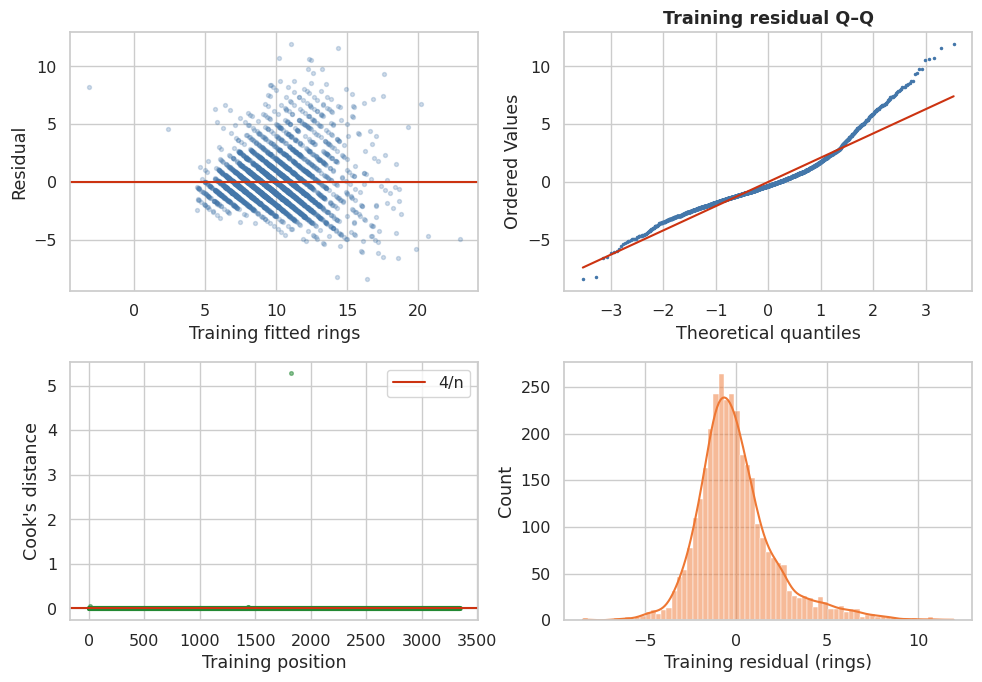

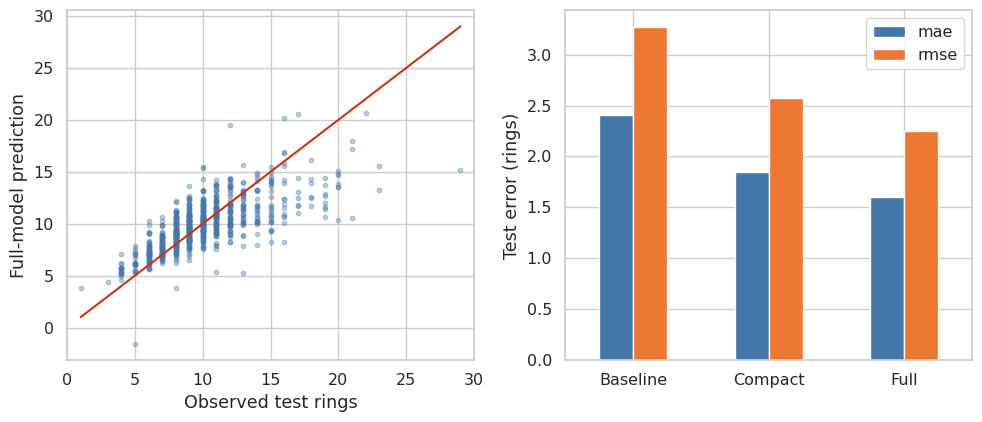

In [15]:
vif=pd.DataFrame({'term':feature_names[1:],'VIF':[variance_inflation_factor(design,i) for i in range(1,design.shape[1])]})
save_table(vif,'vif');display(vif)
bp=het_breuschpagan(ols.resid,design)
cooks=ols.get_influence().cooks_distance[0]
influence=pd.DataFrame({'source_index':train.index,'observed':train.rings,'fitted':ols.fittedvalues,'residual':ols.resid,'cooks_distance':cooks})
save_table(influence,'training_diagnostics')
print('Design rank:',np.linalg.matrix_rank(design),'of',design.shape[1]);print('Breusch–Pagan LM / p:',bp[:2]);print('Cook flags:',int((cooks>4/len(train)).sum()))
fig,axes=plt.subplots(2,2,figsize=(10,7))
axes[0,0].scatter(ols.fittedvalues,ols.resid,s=8,alpha=.25,color='#4477AA');axes[0,0].axhline(0,color='#CC3311');axes[0,0].set(xlabel='Training fitted rings',ylabel='Residual')
stats.probplot(ols.resid,dist='norm',plot=axes[0,1]);axes[0,1].get_lines()[0].set(color='#4477AA',marker='.',markersize=3);axes[0,1].get_lines()[1].set_color('#CC3311');axes[0,1].set_title('Training residual Q–Q')
axes[1,0].scatter(np.arange(len(train)),cooks,s=7,color='#228833',alpha=.5);axes[1,0].axhline(4/len(train),color='#CC3311',label='4/n');axes[1,0].set(xlabel='Training position',ylabel="Cook's distance");axes[1,0].legend()
sns.histplot(ols.resid,kde=True,color='#EE7733',ax=axes[1,1]);axes[1,1].set_xlabel('Training residual (rings)')
save_figure(fig,'08_regression_diagnostics')
fig,axes=plt.subplots(1,2,figsize=(10,4.4))
axes[0].scatter(test.rings,predictions.Full,s=10,alpha=.35,color='#4477AA');axes[0].plot([1,29],[1,29],color='#CC3311');axes[0].set(xlabel='Observed test rings',ylabel='Full-model prediction',xlim=(0,30))
test_metrics.plot.bar(x='model',y=['mae','rmse'],color=['#4477AA','#EE7733'],ax=axes[1],rot=0);axes[1].set(xlabel='',ylabel='Test error (rings)')
save_figure(fig,'09_holdout_evaluation')

### 5.6 Influence sensitivity — training only
A Cook flag is not proof of an error. The primary full model retains every training record. As a sensitivity check only, fit a provisional full model within each inner-training fold, compute its Cook distances, remove observations above4/n inside that same training fold, refit preprocessing and OLS, then evaluate the unchanged validation fold. This prevents validation information from influencing deletion. Coefficient changes on the full training set are reported separately; no sensitivity method is tuned or evaluated on the holdout.

In [16]:
sensitivity_rows=[]
for fold,(inner,valid) in enumerate(folds,1):
    a,b=train.iloc[inner],train.iloc[valid]
    sensitive,keep,_=cook_filter_fit(a[FULL],a.rings,FULL)
    sensitivity_rows.append({'fold':fold,'training_before':len(a),'training_after':int(keep.sum()),'removed':int((~keep).sum()),'validation_n':len(b),**metrics(b.rings,sensitive.predict(b[FULL]))})
sensitivity=pd.DataFrame(sensitivity_rows);save_table(sensitivity,'influence_sensitivity_cv');display(sensitivity)
sensitive,keep,_=cook_filter_fit(train[FULL],train.rings,FULL)
coef_change=pd.DataFrame({'term':feature_names,'primary_scaled':[full['regression'].intercept_,*full['regression'].coef_],'filtered_scaled':[sensitive['regression'].intercept_,*sensitive['regression'].coef_]})
# Different scalers after filtering: compare slopes in the original stored units instead.
filtered_coef=sensitive['regression'].coef_.copy();filtered_scaler=sensitive['preprocess'].named_transformers_['numeric']['scale'];filtered_coef[:7]/=filtered_scaler.scale_
filtered_intercept=sensitive['regression'].intercept_-np.dot(filtered_coef[:7],filtered_scaler.mean_)
coef_change['primary_stored']=original_coefficients.coefficient;coef_change['filtered_stored']=[filtered_intercept,*filtered_coef]
save_table(coef_change,'influence_coefficient_sensitivity');display(coef_change[['term','primary_stored','filtered_stored']])

,fold,training_before,training_after,removed,validation_n,mae,rmse,r2
0,1,2672,2498,174,669,1.570830,2.198608,0.523882
1,2,2673,2497,176,668,1.684615,2.448733,0.517550
2,3,2673,2508,165,668,1.582163,2.205893,0.537267
3,4,2673,2498,175,668,1.449626,2.024696,0.542081
4,5,2673,2505,168,668,1.497127,2.164819,0.506304


,term,primary_stored,filtered_stored
0,Intercept,3.871591,3.495774
1,length,-0.811279,-0.480856
2,diameter,12.195495,10.563265
3,height,8.798581,15.941858
4,whole_weight,9.395209,9.713459
5,shucked_weight,-20.655061,-20.393875
6,viscera_weight,-10.255190,-10.817625
7,shell_weight,8.318961,5.794393
8,sex_I,-0.784001,-0.731726
9,sex_M,0.076031,0.070744


## 6. Synthesis and reproducible exports
Read the outputs together: distribution rejection need not invalidate large-sample mean comparisons, but dependence and sampling bias remain. Association is not causation. Strong collinearity can destabilize conditional coefficients even when predictions improve. Evaluate improvement relative to baseline in ring units, with CV variability and holdout performance. Source Rings+1.5 is an approximate age relation, not additional independent information or a predictor.

The report and slides consume this execution's exported summary, tables and figures. Their builders do not recompute statistical analyses. Personal contribution percentages and video publication are separate external facts and are not generated from code.

In [17]:
# Portable chart snapshots are exported from this same execution.
length_hist,edges=np.histogram(train.length,bins=25,density=True)
weight_hist,w_edges=np.histogram(train.whole_weight,bins=25,density=True)
qq_probs=np.linspace(.005,.995,100)
chart_data={'length_density':{'hist_x':((edges[1:]+edges[:-1])/2).tolist(),'hist_y':length_hist.tolist(),'x':grid.tolist(),'normal':stats.norm.pdf(grid,mu,sd).tolist()},
 'weight_density':{'x':grid_w.tolist(),'normal':stats.norm.pdf(grid_w,mu_w,sd_w).tolist(),'lognormal':stats.lognorm.pdf(grid_w,logsd,scale=np.exp(logmu)).tolist(),'hist_x':((w_edges[1:]+w_edges[:-1])/2).tolist(),'hist_y':weight_hist.tolist()},
 'qq_length':{'x':stats.norm.ppf(qq_probs).tolist(),'y':np.quantile(train.length,qq_probs).tolist()},
 'shell_scatter':{'x':train.shell_weight.tolist(),'y':train.rings.tolist()},
 'holdout':{'x':test.rings.tolist(),'y':predictions.Full.tolist()},
 'residuals':{'x':ols.fittedvalues.tolist(),'y':ols.resid.tolist()},
 'length_group':length_summary.reset_index().to_dict('records'),'contingency_percent':percent.to_dict('index')}
summary={'raw_shape':list(raw.shape),'raw_sha256':raw_hash,'original_missing':int(raw.isna().sum().sum()),'duplicates':int(raw.duplicated().sum()),
 'invalid_height_indices':invalid_height,'train_n':len(train),'test_n':len(test),'train_group_counts':train.sex.value_counts().to_dict(),'raw_group_counts':raw.sex.value_counts().to_dict(),
 'descriptive':descriptive.to_dict('index'),'iqr_counts':outlier_counts.to_dict('index'),'distribution':distribution.to_dict('records'),
 'hypotheses':hypotheses.drop(columns='df2').to_dict('records'),'welch':welch,'chi':chi,'anova':{'F':float(anova.statistic),'df_num':float(anova.df_num),'df_den':float(anova.df_denom),'p':float(anova.pvalue),'classic_F':float(classic.statistic),'classic_p':float(classic.pvalue),'levene_stat':float(levene.statistic),'levene_p':float(levene.pvalue),'eta_squared_descriptive':eta_sq},
 'posthoc':pairwise.to_dict('records') if posthoc else [],'contingency':contingency.to_dict('index'),'correlations':correlations.to_dict('index'),
 'pearson':pearson.to_dict('index'),'spearman':spearman.to_dict('index'),'test_metrics':test_metrics.to_dict('records'),
 'cv':cv.to_dict('records'),'coefficients':coefficients.to_dict('records'),'coefficients_stored':original_coefficients.to_dict('records'),'vif':vif.to_dict('records'),
 'diagnostics':{'rank':int(np.linalg.matrix_rank(design)),'design_columns':int(design.shape[1]),'bp_lm':float(bp[0]),'bp_p':float(bp[1]),'cook_flagged':int((cooks>4/len(train)).sum())},
 'sensitivity':sensitivity.to_dict('records'),'sensitivity_removed_total_train':int((~keep).sum()),'coefficient_sensitivity':coef_change[['term','primary_stored','filtered_stored']].to_dict('records'),'chart_data':chart_data}
dump(ROOT/'results/summary.json',summary)
versions={name:importlib.metadata.version(name) for name in ['numpy','pandas','scipy','seaborn','matplotlib','scikit-learn','statsmodels','nbformat','nbclient','ipykernel']}
artifacts=sorted([*T.glob('*.csv'),*F.glob('*.png'),*F.glob('*.svg'),*(ROOT/'data/processed').glob('*.csv'),ROOT/'results/summary.json'])
dump(ROOT/'results/manifest.json',{'raw_sha256':raw_hash,'split_seed':42,'versions':versions,'artifacts':{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in artifacts}})
print('Completed all six theory sections. Summary and all artifacts exported; no test-driven tuning was performed.')

Completed all six theory sections. Summary and all artifacts exported; no test-driven tuning was performed.
